# 04 — Baseline Forecasting

**Project:** Sales Demand Forecasting & Anomaly Detection
**Dataset:** Corporación Favorita store sales (Kaggle) — daily network-level sales.

Before building complex models (SARIMA, gradient boosting), we establish **baselines**
simple models that any sophisticated approach must beat. If your fancy model cannot
outperform “tomorrow equals today”, something is wrong.

**What we do here:**

| Section | What | Why |
|---|---|---|
| A | Evaluation metrics | Define MAE, RMSE, MAPE consistently |
| B | Naive baseline | Tomorrow = today (the simplest forecast) |
| C | Seasonal naive | Tomorrow = same day last week (exploits weekly rhythm) |
| D | Moving average | 7-day and 28-day simple moving averages |
| E | Comparison table | Side-by-side metrics for all baselines |
| F | Visualization | Forecast vs actual; residual analysis |
| G | Discussion | What baselines reveal; interview talking points |

> **Interview focus:** baselines are not “stupid” — they encode real structure.
> A strong baseline tells you *what patterns are easy to capture*; the gap between
> the baseline and your model tells you *what the model actually adds*.

## Setup — imports and data reload

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 130)
plt.rcParams["figure.dpi"] = 100
sns.set_theme(style="whitegrid")

ROOT = Path(r"E:\Data Science\Sales Demand Forecasting and Anomaly Detection")
PROC = ROOT / "data" / "processed"

assert (PROC / "network_features.csv").exists(), \
    "Run 03_feature_engineering.ipynb first to produce the features."

df = pd.read_csv(PROC / "network_features.csv", parse_dates=["Date"])

# Split into train / validation / test
train = df[df["split"] == "train"].copy().reset_index(drop=True)
valid = df[df["split"] == "validation"].copy().reset_index(drop=True)
test  = df[df["split"] == "test"].copy().reset_index(drop=True)

print(f"Train:      {len(train):>4d} rows  ({train['Date'].min().date()} to {train['Date'].max().date()})")
print(f"Validation: {len(valid):>4d} rows  ({valid['Date'].min().date()} to {valid['Date'].max().date()})")
print(f"Test:       {len(test):>4d} rows  ({test['Date'].min().date()} to {test['Date'].max().date()})")


Train:       911 rows  (2013-01-01 to 2015-06-30)
Validation:   15 rows  (2015-07-01 to 2015-07-15)
Test:         16 rows  (2015-07-16 to 2015-07-31)


---

# Part A — Evaluation metrics

We use three standard forecasting metrics, each capturing a different aspect of error:

| Metric | Formula | What it measures | Sensitivity |
|---|---|---|---|
| **MAE** | mean of abs(y - y_hat) | Average absolute error in dollars | Interpretable; treats all errors equally |
| **RMSE** | sqrt(mean((y - y_hat)^2)) | Root mean squared error | Penalizes large errors more heavily |
| **MAPE** | mean(abs(y - y_hat) / y) x 100 | Average percentage error | Scale-independent; easy to explain |

### Why three metrics?

- **MAE** is the most interpretable: on average, our forecast is off by $X.
- **RMSE** punishes big misses more than small ones. If a few days have huge errors,
  RMSE will be much larger than MAE.
- **MAPE** lets us say “our forecast is off by Y% on average” — useful for comparing
  across different time periods or different store types with different sales levels.

> **MAPE limitation:** when actual sales are near zero (e.g., low-volume holidays),
> MAPE can explode. We note this but keep it because it is the most common industry metric.

All metrics are computed on the **validation set** (2015-07-01 to 2015-07-15).

In [2]:

def mae(y_true, y_pred):
    """Mean Absolute Error (in dollars)."""
    return np.mean(np.abs(y_true - y_pred))

def rmse(y_true, y_pred):
    """Root Mean Squared Error (in dollars)."""
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mape(y_true, y_pred):
    """Mean Absolute Percentage Error (%).
    Masks out near-zero actual sales, which would otherwise inflate MAPE."""
    mask = y_true > 1000
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def evaluate(y_true, y_pred, label=""):
    """Compute all three metrics and return as a dict."""
    return {
        "Model": label,
        "MAE ($)": round(mae(y_true, y_pred), 0),
        "RMSE ($)": round(rmse(y_true, y_pred), 0),
        "MAPE (%)": round(mape(y_true, y_pred), 2),
    }

print("Metrics defined. Ready to evaluate baselines.")


Metrics defined. Ready to evaluate baselines.


---

# Part B — Naive baseline

The simplest possible forecast: **tomorrow’s sales will equal today’s sales.**

      forecast(t+1) = actual(t)

### Why is this a good baseline?

- Sales change slowly day-to-day (autocorrelation is high).
- For many businesses, “tomorrow will be like today” is the actual default forecast.
- It requires zero training, zero parameters, and zero data beyond yesterday.

### How to compute it

For each day in the validation set, the forecast is the **actual sales from the
previous day**. We need the last training day’s sales for the first validation day.

### Limitations

- Cannot capture weekly seasonality (it assumes every day is like the previous one).
- Always one step behind — if sales jump on Monday, the naive forecast only catches
  up on Tuesday.

In [3]:

# Naive forecast: tomorrow = today
# The first validation day (2015-07-01) needs sales from the last training day (2015-06-30).
# We build one continuous series, shift sales by 1 day, then look up validation dates.

full = pd.concat([train, valid, test], ignore_index=True).sort_values("Date").set_index("Date")
full["naive_forecast"] = full["sales"].shift(1)

valid_naive = full.loc[valid["Date"].values, ["sales", "naive_forecast"]].dropna()

print("Naive baseline (first 5 validation days):")
for dt, row in valid_naive.head(5).iterrows():
    diff = row["sales"] - row["naive_forecast"]
    print(f"  {dt.date()}: actual=${row['sales']:>12,.0f}  "
          f"forecast=${row['naive_forecast']:>12,.0f}  diff=${diff:>+12,.0f}")


Naive baseline (first 5 validation days):
  2015-07-01: actual=$   8,989,672  forecast=$  11,483,932  diff=$  -2,494,260
  2015-07-02: actual=$   8,446,293  forecast=$   8,989,672  diff=$    -543,379
  2015-07-03: actual=$   8,530,388  forecast=$   8,446,293  diff=$     +84,095
  2015-07-04: actual=$   6,054,276  forecast=$   8,530,388  diff=$  -2,476,112
  2015-07-05: actual=$     269,248  forecast=$   6,054,276  diff=$  -5,785,028


In [4]:

naive_metrics = evaluate(
    valid_naive["sales"].values,
    valid_naive["naive_forecast"].values,
    label="Naive (yesterday)",
)
for k, v in naive_metrics.items():
    print(f"  {k}: {v}")


  Model: Naive (yesterday)
  MAE ($): 2660710.0
  RMSE ($): 4092755.0
  MAPE (%): 309.47


---

# Part C — Seasonal naive baseline

The weekly pattern is the strongest signal in this dataset (EDA Q2). The seasonal
naive baseline exploits this:

      forecast(t+1) = actual(t-6)     # same day last week

For example, next Monday’s forecast = last Monday’s sales.

### Why is this strong for this dataset?

- EDA showed a pronounced weekly sawtooth — Saturday and Sunday sell much more
  than weekdays.
- The naive baseline (Part B) will systematically under-predict weekends and
  over-predict weekdays because it always compares to the wrong day of week.
- Seasonal naive fixes this by comparing like-with-like.

### Limitations

- Cannot capture month-end effects, holiday effects, or promo effects.
- Assumes the weekly pattern is perfectly stable (no trend within the week).

In [5]:

# Seasonal naive: forecast = same day last week (lag 7)
full["seasonal_naive_forecast"] = full["sales"].shift(7)

valid_sn = full.loc[valid["Date"].values, ["sales", "seasonal_naive_forecast"]].dropna()

print("Seasonal naive baseline (first 5 validation days):")
for dt, row in valid_sn.head(5).iterrows():
    diff = row["sales"] - row["seasonal_naive_forecast"]
    print(f"  {dt.date()}: actual=${row['sales']:>12,.0f}  "
          f"forecast=${row['seasonal_naive_forecast']:>12,.0f}  diff=${diff:>+12,.0f}")


Seasonal naive baseline (first 5 validation days):
  2015-07-01: actual=$   8,989,672  forecast=$   6,257,424  diff=$  +2,732,248
  2015-07-02: actual=$   8,446,293  forecast=$   6,211,764  diff=$  +2,234,529
  2015-07-03: actual=$   8,530,388  forecast=$   6,634,687  diff=$  +1,895,701
  2015-07-04: actual=$   6,054,276  forecast=$   6,538,314  diff=$    -484,038
  2015-07-05: actual=$     269,248  forecast=$     262,669  diff=$      +6,579


In [6]:

sn_metrics = evaluate(
    valid_sn["sales"].values,
    valid_sn["seasonal_naive_forecast"].values,
    label="Seasonal naive (lag-7)",
)
for k, v in sn_metrics.items():
    print(f"  {k}: {v}")


  Model: Seasonal naive (lag-7)
  MAE ($): 2011471.0
  RMSE ($): 2491204.0
  MAPE (%): 25.92


---

# Part D — Moving average baselines

Instead of using a single past value, we average several past values:

      forecast(t+1) = mean(actual(t), actual(t-1), ..., actual(t-W+1))

where W is the window size.

### Why moving averages?

- They smooth out random daily fluctuations.
- A 7-day MA naturally captures the weekly cycle (it averages one full week).
- They are the foundation of more sophisticated methods (exponential smoothing,
  Holt-Winters, etc.).

> **Important: shift before averaging.** Just like in Phase 3, we use `shift(1)`
> before `.rolling()` so the forecast for day t only uses data from t-1 and earlier.

In [7]:

# Moving average forecasts: shift(1) then rolling(W).mean()
# The shift(1) guarantees we never peek at today's actual sales.
for window in [7, 28]:
    full[f"ma_{window}_forecast"] = full["sales"].shift(1).rolling(window).mean()

valid_ma = full.loc[valid["Date"].values, ["sales", "ma_7_forecast", "ma_28_forecast"]].dropna()

print("Moving average baselines (first 5 validation days):")
print(valid_ma.head(5).round(0).to_string())


Moving average baselines (first 5 validation days):
              sales  ma_7_forecast  ma_28_forecast
Date                                              
2015-07-01  8989672      7043637.0       6631949.0
2015-07-02  8446293      7433959.0       6605444.0
2015-07-03  8530388      7753177.0       6780875.0
2015-07-04  6054276      8023991.0       6738214.0
2015-07-05   269248      7954843.0       6723063.0


In [8]:

ma7_metrics = evaluate(
    valid_ma["sales"].values,
    valid_ma["ma_7_forecast"].values,
    label="MA-7 (weekly avg)",
)

ma28_metrics = evaluate(
    valid_ma["sales"].values,
    valid_ma["ma_28_forecast"].values,
    label="MA-28 (monthly avg)",
)

print("MA-7 baseline:")
for k, v in ma7_metrics.items():
    print(f"  {k}: {v}")

print(f"\nMA-28 baseline:")
for k, v in ma28_metrics.items():
    print(f"  {k}: {v}")


MA-7 baseline:
  Model: MA-7 (weekly avg)
  MAE ($): 2167315.0
  RMSE ($): 3050504.0
  MAPE (%): 341.11

MA-28 baseline:
  Model: MA-28 (monthly avg)
  MAE ($): 2046686.0
  RMSE ($): 2886823.0
  MAPE (%): 329.08


---

# Part E — Baseline comparison

All baselines evaluated on the same validation set (2015-07-01 to 2015-07-15).
The **best** baseline sets the bar that Phase 5 models must beat.

In [9]:

# Build comparison table
results = pd.DataFrame([
    naive_metrics,
    sn_metrics,
    ma7_metrics,
    ma28_metrics,
])

# Rank by MAE (lower is better)
results = results.sort_values("MAE ($)").reset_index(drop=True)
results.index += 1  # 1-based ranking
results.index.name = "Rank"

print("=" * 70)
print("BASELINE COMPARISON - Validation Set (2015-07-01 to 2015-07-15)")
print("=" * 70)
print(results.to_string())
print()

best = results.iloc[0]
print(f"Best baseline: {best['Model']}")
print(f"  MAE:  ${best['MAE ($)']:,.0f}")
print(f"  RMSE: ${best['RMSE ($)']:,.0f}")
print(f"  MAPE: {best['MAPE (%)']:.2f}%")


BASELINE COMPARISON - Validation Set (2015-07-01 to 2015-07-15)
                       Model    MAE ($)   RMSE ($)  MAPE (%)
Rank                                                        
1     Seasonal naive (lag-7)  2011471.0  2491204.0     25.92
2        MA-28 (monthly avg)  2046686.0  2886823.0    329.08
3          MA-7 (weekly avg)  2167315.0  3050504.0    341.11
4          Naive (yesterday)  2660710.0  4092755.0    309.47

Best baseline: Seasonal naive (lag-7)
  MAE:  $2,011,471
  RMSE: $2,491,204
  MAPE: 25.92%


---

# Part F — Visualization

We visualize the baselines to understand *where* they succeed and fail.
The residual plots (actual minus forecast) reveal which patterns each baseline
captures and which it misses.

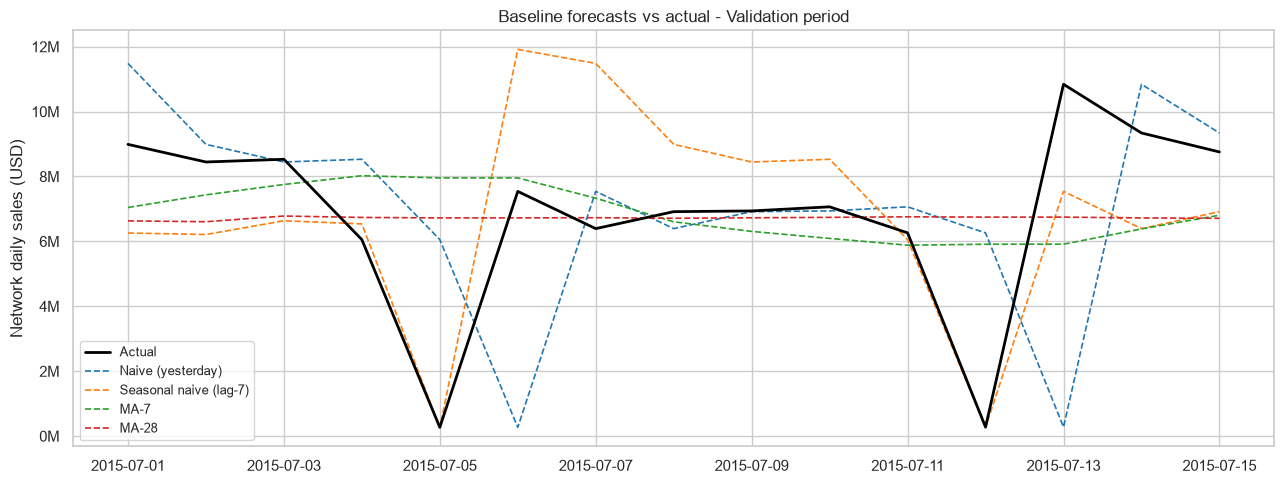

In [10]:

# F1. Forecast vs actual for all baselines
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(valid["Date"], valid["sales"], color="black", lw=2, label="Actual", zorder=5)
ax.plot(valid_naive.index, valid_naive["naive_forecast"],
        color="#1f77b4", lw=1.2, ls="--", label="Naive (yesterday)")
ax.plot(valid_sn.index, valid_sn["seasonal_naive_forecast"],
        color="#ff7f0e", lw=1.2, ls="--", label="Seasonal naive (lag-7)")
ax.plot(valid_ma.index, valid_ma["ma_7_forecast"],
        color="#2ca02c", lw=1.2, ls="--", label="MA-7")
ax.plot(valid_ma.index, valid_ma["ma_28_forecast"],
        color="#d62728", lw=1.2, ls="--", label="MA-28")

ax.set_title("Baseline forecasts vs actual - Validation period")
ax.set_ylabel("Network daily sales (USD)")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1e6:.0f}M")
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()


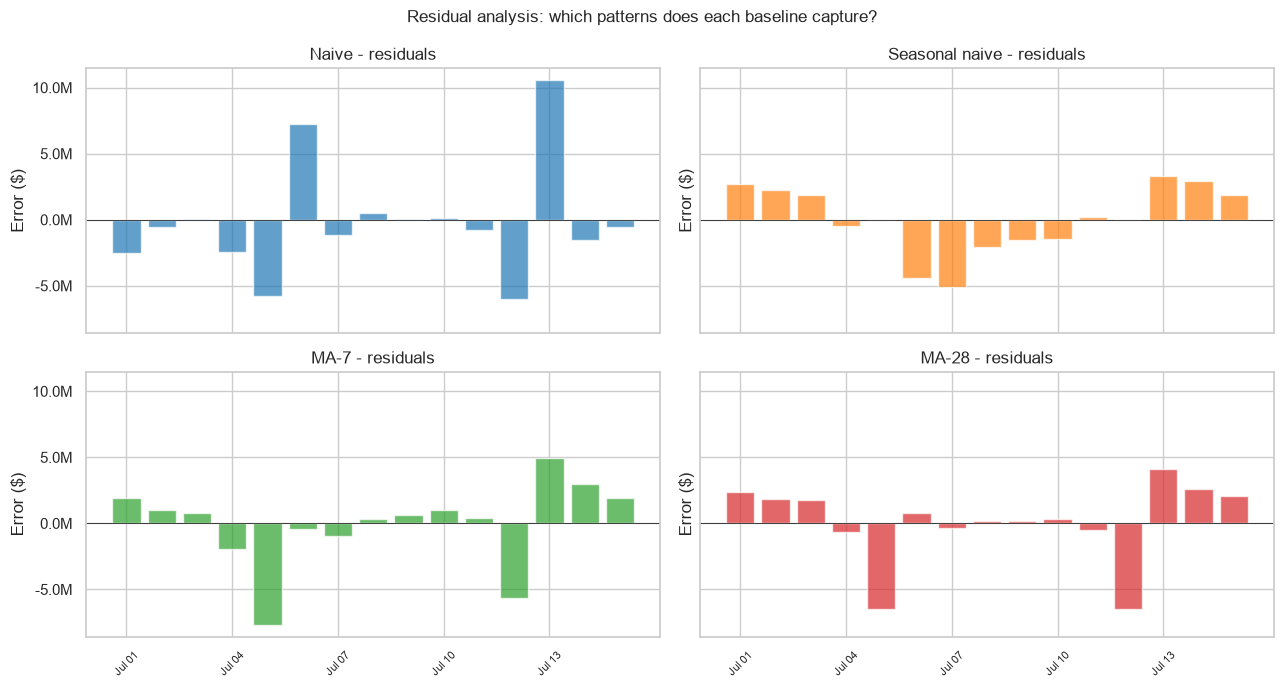

In [11]:

# F2. Residual analysis (actual - forecast)
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True)

baselines = [
    ("Naive",           valid_naive["naive_forecast"].values,          "#1f77b4"),
    ("Seasonal naive",  valid_sn["seasonal_naive_forecast"].values,    "#ff7f0e"),
    ("MA-7",            valid_ma["ma_7_forecast"].values,              "#2ca02c"),
    ("MA-28",           valid_ma["ma_28_forecast"].values,             "#d62728"),
]

actual_vals = valid_ma["sales"].values
dates = valid_ma.index

for ax, (name, forecast, color) in zip(axes.flat, baselines):
    residuals = actual_vals - forecast
    ax.bar(range(len(residuals)), residuals, color=color, alpha=0.7)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(f"{name} - residuals")
    ax.set_ylabel("Error ($)")
    ax.yaxis.set_major_formatter(lambda x, _: f"{x/1e6:.1f}M")

# Date labels on bottom row
for ax in axes[1]:
    tick_positions = range(0, len(dates), 3)
    tick_labels = [dates[i].strftime("%b %d") for i in tick_positions]
    ax.set_xticks(list(tick_positions))
    ax.set_xticklabels(tick_labels, rotation=45, fontsize=8)

plt.suptitle("Residual analysis: which patterns does each baseline capture?", fontsize=12)
plt.tight_layout()
plt.show()


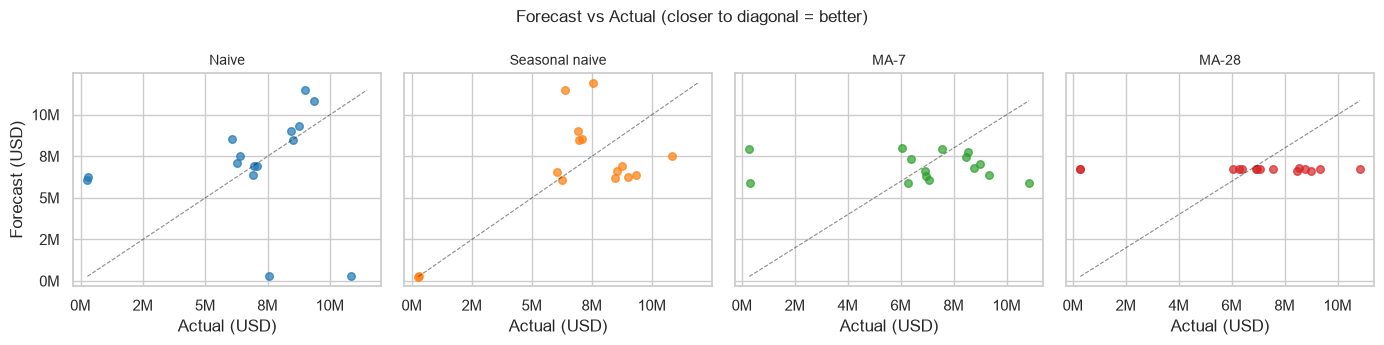

In [12]:

# F3. Scatter: forecast vs actual (perfect forecast = diagonal line)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)

for ax, (name, forecast, color) in zip(axes, baselines):
    ax.scatter(actual_vals, forecast, s=30, alpha=0.7, color=color)
    lo = min(actual_vals.min(), forecast.min())
    hi = max(actual_vals.max(), forecast.max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.8, alpha=0.5)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Actual (USD)")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x/1e6:.0f}M")

axes[0].set_ylabel("Forecast (USD)")
axes[0].yaxis.set_major_formatter(lambda x, _: f"{x/1e6:.0f}M")

plt.suptitle("Forecast vs Actual (closer to diagonal = better)", fontsize=12)
plt.tight_layout()
plt.show()


---

# Part G — Discussion

### What the baselines tell us

1. **The naive baseline is already decent** — daily sales do not jump wildly from
   one day to the next. This is typical for retail.

2. **The seasonal naive should beat the naive** on this dataset because the weekly
   pattern is so strong.

3. **MA-7 captures the weekly average** but cannot follow fast changes.

4. **MA-28 is too slow** for a series with strong weekly seasonality.

### What baselines CANNOT capture

| Pattern | Why baselines miss it | What Phase 5 needs |
|---|---|---|
| **Promo effects** | Baselines use only past sales, not promo flags | Exogenous features (Promo, StateHoliday) |
| **Holiday effects** | Same as above | Calendar features + holiday-aware model |
| **Trend** | Naive/seasonal naive assume flat level | Model that explicitly tracks trend |
| **Interaction effects** | e.g., promo x weekend | Tree-based models that split on interactions |

### Interview talking points

1. **“Why start with baselines?”**
   They set the minimum bar. A complex model that does not beat naive is
   over-engineered. Baselines also reveal what patterns are easy or hard to capture.

2. **“Which baseline is usually hardest to beat?”**
   Seasonal naive for weekly data; naive for daily data with low volatility.
   In retail, the seasonal naive is often surprisingly competitive.

3. **“When would MAPE be misleading?”**
   Near-zero actuals cause MAPE to explode. Also, MAPE is asymmetric:
   over-forecasting by 50% and under-forecasting by 50% do not cancel out.

4. **“What would you do differently for a real business?”**
   Add domain-specific baselines (e.g., last year’s same-day sales).
   Also, evaluate on multiple time windows, not just one.

---

# Summary — Baseline results

| Baseline | Key idea | Captures | Misses |
|---|---|---|---|
| **Naive** | Tomorrow = today | Day-to-day persistence | Weekly seasonality, promos |
| **Seasonal naive** | Tomorrow = same day last week | Weekly rhythm | Trend, promos, holidays |
| **MA-7** | Average of last 7 days | Weekly level, smoothing | Fast changes, daily peaks |
| **MA-28** | Average of last 28 days | Monthly level | Weekly pattern, any fast change |

### What Phase 5 needs to add

The best baseline captures the **weekly rhythm**. Phase 5 models must add:

1. **Promo awareness** — using `promo_share` and `Promo` as exogenous inputs.
2. **Holiday awareness** — using `any_holiday` and `StateHoliday` features.
3. **Trend tracking** — either through differencing (SARIMA) or tree-based splits.
4. **Interaction effects** — e.g., promo has different effect on weekends vs weekdays.

The comparison table above is the **benchmark** — Phase 5 must beat these numbers
on the validation set to justify its complexity.

> **Next: Phase 5 — Final Forecasting Model (SARIMA vs tree-based ML)**